# Step 3: Load, check and clean the data

**Rule of this notebook: the raw files in `data-pack/data/` are only ever read. Cleaned copies go to `data-clean/`.**

Run the cells top to bottom (Shift+Enter). Each section says what it does, why, and how to confirm it worked.
Requires: `pip install pandas` and a Jupyter kernel (VS Code Jupyter extension).

## 3.1 Setup and load (everything as plain text)

Why text: if pandas guesses types, the string `NA` silently becomes "missing" and `01-04-2024` may be read month-first.
We read everything as text, then convert on purpose.

In [1]:
import os, re
import pandas as pd
from IPython.display import display, HTML

RAW = os.path.join('..', 'data-pack', 'data')   # read-only
OUT = os.path.join('..', 'data-clean')          # we write here
os.makedirs(OUT, exist_ok=True)

LOG = []   # one line per fix: what, where, how many, what we did
def log(file, column, issue, rows, action):
    LOG.append(dict(file=file, column=column, issue=issue, rows=int(rows), action=action))

names = ['sku_master','stockist_master','batch_master','primary_sales','expiry_claims','cnf_stock_snapshot','claim_emails']

# RAW_ORIG = every file exactly as it is on disk (text), plus src_row = its line number in the CSV file (header = line 1).
# This is the 'before' picture used by the audit trail.
RAW_ORIG = {}
for n in names:
    d = pd.read_csv(os.path.join(RAW, n + '.csv'), dtype=str, keep_default_na=False)
    d.insert(0, 'src_row', range(2, len(d) + 2))
    RAW_ORIG[n] = d

def load(name):
    '''Working copy: same as RAW_ORIG but with leading/trailing spaces removed.'''
    df = RAW_ORIG[name].copy()
    cols = [c for c in df.columns if c != 'src_row']
    df[cols] = df[cols].apply(lambda s: s.str.strip())
    return df

raw = {n: load(n) for n in names}
for n, df in raw.items():
    print(f'{n:22s} rows={len(df):>6}  cols={len(df.columns) - 1}')

sku_master             rows=    36  cols=9
stockist_master        rows=   156  cols=8
batch_master           rows=   663  cols=6
primary_sales          rows= 93809  cols=12
expiry_claims          rows=  4526  cols=17
cnf_stock_snapshot     rows=  5015  cols=8
claim_emails           rows=    30  cols=6


**Check:** you should see `sku_master 36`, `stockist_master 156`, `batch_master 663`, `primary_sales 93809`, `expiry_claims 4526`, `cnf_stock_snapshot 5015`, `claim_emails 30`.

## 3.2 Look for problems (nothing is changed here)

Blank cells per column, and the *shape* of each value (9 = digit, A = capital, a = lowercase). A column with several shapes is a warning sign.

In [2]:
def shape(s): return re.sub(r'[a-z]','a',re.sub(r'[A-Z]','A',re.sub(r'\d','9',s)))

for n, df in raw.items():
    print('\n==', n)
    blanks = {c:int((df[c]=='').sum()) for c in df.columns if c != 'src_row' and (df[c]=='').sum()}
    print('  blank cells:', blanks)
    for c in [c for c in df.columns if c != 'src_row']:
        pc = df[c][df[c]!=''].map(shape).value_counts()
        if 1 < len(pc) <= 6 and df[c].nunique() > 12:
            print(f'  {c}: shapes', pc.to_dict())


== sku_master
  blank cells: {}
  pts_inr: shapes {'99.9': 23, '999.9': 12, '9.9': 1}
  mrp_inr: shapes {'999.9': 21, '99.9': 15}

== stockist_master
  blank cells: {'city': 4, 'appointed_on': 150}

== batch_master
  blank cells: {'mfg_site': 13}
  mfg_date: shapes {'99-99-9999': 599, '9999-99-99': 64}
  expiry_date: shapes {'99-99-9999': 595, '9999-99-99': 68}
  batch_qty_packs: shapes {'99999': 332, '999999': 331}

== primary_sales
  blank cells: {'batch_no': 2654, 'ordered_qty': 3069, 'scheme_code': 48446}
  invoice_date: shapes {'99-99-9999': 81543, '9999-99-99': 7511, '99-Aaa-9999': 4755}
  stockist_code: shapes {'AAA9999': 92486, 'aaa9999': 1323}
  ordered_qty: shapes {'999': 64657, '9999': 25087, '99': 992, '99999': 4}
  invoiced_qty: shapes {'999': 66776, '9999': 21328, '9': 2876, '99': 2829}
  free_qty: shapes {'9': 82887, '999': 6607, '99': 4249, '9999': 66}
  pts_inr: shapes {'99.9': 59387, '999.9': 32580, '9.9': 1842}
  scheme_code: shapes {'AA': 16347, '-': 16294, 'AA-AA9

**Check:** you should see the date columns with 2-3 shapes, `stockist_code` with `AAA9999` / `aaa9999`, `sku_code` in claims with `AAA-9999`, `cnf_code` in the snapshot with `CFE01`-style codes, and `scheme_code` with `NA` / `-` / blank.

## 3.3 Fix: helper functions

Small, reusable pieces. Read them once; they are used in the cells below.

In [3]:
def to_date(s, f, c):
    '''Parse the three date formats in these files. Stops with an error if any value fits none.'''
    iso = s.str.fullmatch(r'\d{4}-\d{2}-\d{2}')            # 2024-04-01
    dmy = s.str.fullmatch(r'\d{2}-\d{2}-\d{4}')            # 01-04-2024 (day first)
    mon = s.str.fullmatch(r'\d{2}-[A-Za-z]{3}-\d{4}')       # 01-Apr-2024
    blank = s == ''
    bad = ~(iso | dmy | mon | blank)
    if bad.any():
        raise ValueError(f'{f}.{c}: unparsed dates {s[bad].unique()[:5]}')
    out = pd.Series(pd.NaT, index=s.index, dtype='datetime64[ns]')
    out[iso] = pd.to_datetime(s[iso], format='%Y-%m-%d')
    out[dmy] = pd.to_datetime(s[dmy], format='%d-%m-%Y')
    out[mon] = pd.to_datetime(s[mon], format='%d-%b-%Y')
    n = int((iso | mon).sum())
    if n: log(f, c, 'mixed date formats (ISO / dd-Mon-yyyy / dd-mm-yyyy)', n, 'parsed to one date type')
    return out

def num(s):
    return pd.to_numeric(s.str.replace(',', '', regex=False), errors='coerce')

def fix_codes(df, f):
    if 'stockist_code' in df:
        n = int((df.stockist_code != df.stockist_code.str.upper()).sum())
        df['stockist_code'] = df.stockist_code.str.upper()
        if n: log(f, 'stockist_code', 'lowercase code', n, 'uppercased (spaces were stripped on load)')
    if 'sku_code' in df:
        n = int(df.sku_code.str.contains('-').sum())
        df['sku_code'] = df.sku_code.str.upper().str.replace('-', '', regex=False)
        if n: log(f, 'sku_code', 'hyphen form PFL-1301', n, 'hyphen removed')
    if 'batch_no' in df:
        n = int((df.batch_no != df.batch_no.str.upper()).sum())
        df['batch_no'] = df.batch_no.str.upper()
        if n: log(f, 'batch_no', 'lowercase batch', n, 'uppercased')
    if 'cnf_code' in df:
        m = ~df.cnf_code.str.contains('-') & (df.cnf_code != '')
        df.loc[m, 'cnf_code'] = df.loc[m, 'cnf_code'].str.replace(r'^CF(?=[A-Z]\d)', 'CF-', regex=True)
        if m.any(): log(f, 'cnf_code', 'CFE01 instead of CF-E01', m.sum(), 'hyphen inserted')
    return df

DROPPED, CHANGED, FLAGGED = {}, [], []

def drop_exact_dups(df, f, value_col=None):
    '''Drop rows identical in EVERY field (run AFTER normalising codes). Keeps the first; records the rest as proof.'''
    cols = [c for c in df.columns if c != 'src_row']
    first = df.groupby(cols, dropna=False)['src_row'].transform('first')
    mask = df.duplicated(cols, keep='first')
    d = df[mask].copy()
    d['duplicate_of_src_row'] = first[mask]
    d['drop_reason'] = 'exact duplicate after normalisation'
    if len(d):
        val = float(d[value_col].sum()) if value_col else float('nan')
        log(f, '(row)', f'exact duplicate rows after normalisation; value INR {val:,.0f}', len(d), 'dropped (kept first); see audit/dropped_rows_*.csv')
        DROPPED[f] = d
    return df[~mask].reset_index(drop=True)

def audit_changes(f, key, rules, after):
    '''Compare the untouched original with the cleaned frame (before any rows are dropped) and list every cell that changed.'''
    before = RAW_ORIG[f]
    parts = []
    for c in before.columns:
        if c == 'src_row' or c not in after.columns: continue
        b, a = before[c], after[c]
        if a.dtype.kind == 'M':      # dates: list real changes (dd-Mon-yyyy -> ISO). dd-mm-yyyy and already-ISO values keep the same date and are not listed
            new = a.dt.strftime('%Y-%m-%d').fillna('')
            changed = (b != '') & (b != new) & ~b.str.fullmatch(r'\d{2}-\d{2}-\d{4}')   # only real changes (e.g. 01-Apr-2024 -> 2024-04-01)
        elif a.dtype.kind in 'fi':   # numbers: list the ones that were text with commas
            new = b.str.replace(',', '', regex=False)
            changed = b.str.contains(',', regex=False)
        else:                        # text: spaces trimmed, case, hyphens, NO_SCHEME ...
            new = a
            changed = b != a
        if changed.any():
            parts.append(pd.DataFrame({'file': f, 'src_row': before.loc[changed, 'src_row'], 'key': before.loc[changed, key],
                                       'column': c, 'old_value': b[changed], 'new_value': new[changed],
                                       'rule': rules.get(c, 'standardised')}))
    if parts: CHANGED.append(pd.concat(parts, ignore_index=True))

def collect_flags(f, df, key, flag_cols):
    for fl in flag_cols:
        m = df[fl]
        FLAGGED.append(pd.DataFrame({'file': f, 'src_row': df.loc[m, 'src_row'], 'key': df.loc[m, key], 'flag': fl}))

## 3.3a Masters (SKU, stockist, batch)

In [4]:
sku = raw['sku_master'].copy()
for c in ['shelf_life_months', 'pts_inr', 'mrp_inr']: sku[c] = num(sku[c])

stk = raw['stockist_master'].copy()
stk['appointed_on'] = to_date(stk.appointed_on, 'stockist_master', 'appointed_on')
log('stockist_master', 'appointed_on', 'blank: not migrated for stockists active before Apr 2024 (01 p3 s5.3, documented)', stk.appointed_on.isna().sum(), 'left blank')
log('stockist_master', 'city', 'blank', (stk.city == '').sum(), 'left blank')

bat = fix_codes(raw['batch_master'].copy(), 'batch_master')
for c in ['mfg_date', 'expiry_date']: bat[c] = to_date(bat[c], 'batch_master', c)
bat['batch_qty_packs'] = num(bat.batch_qty_packs)
log('batch_master', 'mfg_site', 'blank (all others are GOA-01)', (bat.mfg_site == '').sum(), 'left blank')
audit_changes('sku_master', 'sku_code', {}, sku)
audit_changes('stockist_master', 'stockist_code', {}, stk)
audit_changes('batch_master', 'batch_no', {'mfg_date': 'mixed date format -> date', 'expiry_date': 'mixed date format -> date'}, bat)
print(sku.shape, stk.shape, bat.shape)

(36, 10) (156, 9) (663, 7)


## 3.3b Primary sales

- three spellings of "no scheme" (blank, `NA`, `-`) become `NO_SCHEME`
- exact duplicates dropped **after** codes are standardised
- flags added, nothing deleted or filled: cancelled lines (blank batch = line not supplied), split-line continuations (ordered_qty is on the first row of a split order line only, `01` p3 §5.4), same-batch split picks. **A blank `ordered_qty` is documented behaviour, not missing data.**

In [5]:
ps = fix_codes(raw['primary_sales'].copy(), 'primary_sales')
ps['invoice_date'] = to_date(ps.invoice_date, 'primary_sales', 'invoice_date')
commas = int(ps.net_value_inr.str.contains(',').sum())
for c in ['ordered_qty', 'invoiced_qty', 'free_qty', 'pts_inr', 'net_value_inr']: ps[c] = num(ps[c])
log('primary_sales', 'net_value_inr', 'numbers stored as text with commas (137,112.00)', commas, 'converted to numbers')

no = ps.scheme_code.isin(['', 'NA', '-'])
log('primary_sales', 'scheme_code', 'no scheme written as blank / NA / -', no.sum(), "set to 'NO_SCHEME'")
ps.loc[no, 'scheme_code'] = 'NO_SCHEME'
audit_changes('primary_sales', 'invoice_no', {'invoice_date': 'mixed date format -> date', 'scheme_code': "blank/NA/- -> NO_SCHEME", 'net_value_inr': 'text with comma -> number',
              'stockist_code': 'trim spaces / uppercase'}, ps)

ps = drop_exact_dups(ps, 'primary_sales', 'net_value_inr')

# 01 p3 s5.4: one row per invoice line per batch. A sales-order line split across batches repeats, with ordered_qty on the FIRST row only.
# Blank batch = line not supplied. So the unit for short-supply tests is the ORDER LINE (invoice_no + sku_code), not the row.
ps['is_cancelled_line'] = ps.invoiced_qty == 0                       # blank batch: line not supplied
ps['split_line_continuation'] = ps.ordered_qty.isna()                # ordered_qty blank on a later row of a split line (documented, not missing)
ps['same_batch_split_pick'] = ps.duplicated(['invoice_no','sku_code','batch_no'], keep=False) & ~ps.is_cancelled_line
# proof that the blank order quantities are split-line continuations: every one has an earlier row in the same order line WITH an ordered_qty
og = ps.groupby(['invoice_no', 'sku_code']).ordered_qty.transform('count')
assert (og[ps.split_line_continuation] >= 1).all()
log('primary_sales', 'invoiced_qty', 'zero-invoiced line, blank batch = line not supplied (01 p3 s5.4, documented)', ps.is_cancelled_line.sum(), 'kept; flagged is_cancelled_line')
log('primary_sales', 'ordered_qty', 'blank on later rows of a split order line (01 p3 s5.4, documented; every one has an ordered_qty on another row of the same invoice+SKU)', ps.split_line_continuation.sum(), 'left blank; flagged split_line_continuation; test short supply per order line (invoice_no+sku_code), not per row')
log('primary_sales', 'invoice_no+sku+batch', 'same batch repeated within one order line (split picks; invoiced qty per line never exceeds ordered)', ps.same_batch_split_pick.sum(), 'kept; flagged same_batch_split_pick; NOT an error')
collect_flags('primary_sales', ps, 'invoice_no', ['is_cancelled_line', 'split_line_continuation', 'same_batch_split_pick'])
print(ps.shape)

(93063, 16)


## 3.3c Expiry claims

In [6]:
ec = fix_codes(raw['expiry_claims'].copy(), 'expiry_claims')
m = ec.original_invoice_ref.str.startswith('INV-')
ec.loc[m, 'original_invoice_ref'] = ec.loc[m, 'original_invoice_ref'].str.replace('INV-', 'INV/', n=1, regex=False)
if m.any(): log('expiry_claims', 'original_invoice_ref', 'INV-S02/.. instead of INV/S02/..', m.sum(), 'standardised to INV/')

for c in ['claim_date', 'expiry_date_as_claimed', 'credit_note_date']: ec[c] = to_date(ec[c], 'expiry_claims', c)
commas = int(ec.credit_value_inr.str.contains(',').sum())
for c in ['qty_claimed', 'claim_value_inr', 'credit_value_inr']: ec[c] = num(ec[c])
audit_changes('expiry_claims', 'claim_no', {'claim_date': 'mixed date format -> date', 'expiry_date_as_claimed': 'mixed date format -> date', 'credit_note_date': 'mixed date format -> date',
              'credit_value_inr': 'text with comma -> number', 'sku_code': 'PFL-1301 -> PFL1301', 'stockist_code': 'trim spaces / uppercase', 'batch_no': 'uppercase',
              'original_invoice_ref': 'INV-.. -> INV/..'}, ec)
log('expiry_claims', 'credit_value_inr', 'numbers stored as text with commas', commas, 'converted to numbers')
log('expiry_claims', 'claim_value_inr', 'blank', ec.claim_value_inr.isna().sum(), 'left blank (not derived; R5 decision)')

ec = drop_exact_dups(ec, 'expiry_claims', 'claim_value_inr')
ec['invoice_ref_missing'] = ec.original_invoice_ref == ''
collect_flags('expiry_claims', ec, 'claim_no', ['invoice_ref_missing'])
print(ec.shape)

(4503, 19)


## 3.3d Stock snapshot and emails

Rows with the same date, C&F, SKU and batch but different `qty_on_hand_packs` are **both kept and flagged**. We do not add or drop them until the client explains them.

In [7]:
sn = fix_codes(raw['cnf_stock_snapshot'].copy(), 'cnf_stock_snapshot')
sn['snapshot_date'] = to_date(sn.snapshot_date, 'cnf_stock_snapshot', 'snapshot_date')
sn['expiry_date'] = to_date(sn.expiry_date, 'cnf_stock_snapshot', 'expiry_date')
commas = int(sn.qty_on_hand_packs.str.contains(',').sum())
for c in ['qty_on_hand_packs', 'avg_monthly_outward_packs']: sn[c] = num(sn[c])
log('cnf_stock_snapshot', 'qty_on_hand_packs', 'numbers stored as text with commas (e.g. 1,234)', commas, 'converted to numbers')
audit_changes('cnf_stock_snapshot', 'sku_code', {'cnf_code': 'CFE01 -> CF-E01', 'qty_on_hand_packs': 'text with comma -> number', 'snapshot_date': 'date format',
              'expiry_date': 'mixed date format -> date'}, sn)
sn = drop_exact_dups(sn, 'cnf_stock_snapshot')

sn['is_stockout_row'] = (sn.batch_no == '') & (sn.qty_on_hand_packs == 0)
has_batch = sn.batch_no != ''
sn['qty_conflict'] = has_batch & sn.duplicated(['snapshot_date','cnf_code','sku_code','batch_no'], keep=False)
log('cnf_stock_snapshot', 'batch_no+expiry_date', 'blank batch with qty 0 = SKU out of stock at the C&F (01 p3 s5.5, documented)', sn.is_stockout_row.sum(), 'kept; flagged is_stockout_row')
log('cnf_stock_snapshot', 'qty_on_hand_packs', 'same date/C&F/SKU/batch with different qty', sn.qty_conflict.sum(), 'BOTH kept, flagged qty_conflict; not summed; ask client')

em = raw['claim_emails'].copy()
em['received_date'] = to_date(em.received_date, 'claim_emails', 'received_date')
audit_changes('claim_emails', 'email_id', {'received_date': 'mixed date format -> date'}, em)
collect_flags('cnf_stock_snapshot', sn, 'sku_code', ['is_stockout_row', 'qty_conflict'])
log('claim_emails', 'stockist_code_by_mailbox_rule', 'blank (sender not matched)', (em.stockist_code_by_mailbox_rule == '').sum(), 'left blank')
print(sn.shape, em.shape)

(5015, 11) (30, 7)


## 3.3e Save the cleaned files and the AUDIT TRAIL

Four kinds of proof go to `data-clean/audit/`:

| File | What it proves |
|---|---|
| `dropped_rows_<file>.csv` | every row removed, in full, with the `src_row` of the row it duplicates |
| `changed_cells.csv` | every cell altered: file, source row, key, column, old value, new value, rule |
| `flagged_rows.csv` | rows kept but marked (cancelled line, quantity conflict, ...) |
| `cleaning_log.csv` | the rules applied: what, why, how many rows (must agree with the row files) |
| `audit_summary.csv` | per file: rows in, dropped, out, cells changed, rows flagged. **rows_in - dropped must equal rows_out** |

`src_row` is the line number in the raw CSV (header = line 1), so any row can be found in the original file.

In [8]:
AUD = os.path.join(OUT, 'audit'); os.makedirs(AUD, exist_ok=True)

clean = dict(sku_master=sku, stockist_master=stk, batch_master=bat, primary_sales=ps,
             expiry_claims=ec, cnf_stock_snapshot=sn, claim_emails=em)
for n, df in clean.items():
    df.to_csv(os.path.join(OUT, n + '.csv'), index=False)

changes = pd.concat(CHANGED, ignore_index=True)
changes['row_later_dropped'] = [(f in DROPPED) and (r in set(DROPPED[f].src_row)) for f, r in zip(changes.file, changes.src_row)]
changes.to_csv(os.path.join(AUD, 'changed_cells.csv'), index=False)
flags = pd.concat(FLAGGED, ignore_index=True)
flags.to_csv(os.path.join(AUD, 'flagged_rows.csv'), index=False)
for f, d in DROPPED.items():
    d.to_csv(os.path.join(AUD, f'dropped_rows_{f}.csv'), index=False)

value_col = {'primary_sales': 'net_value_inr', 'expiry_claims': 'claim_value_inr'}
rows = []
for f in names:
    rin, rdrop, rout = len(RAW_ORIG[f]), len(DROPPED.get(f, [])), len(clean[f])
    assert rin - rdrop == rout, (f, rin, rdrop, rout)          # nothing lost or invented
    ch, fl = changes[changes.file == f], flags[flags.file == f]
    rows.append(dict(file=f, rows_in=rin, rows_dropped=rdrop, rows_out=rout,
                     dropped_value_inr=round(float(DROPPED[f][value_col[f]].sum())) if f in DROPPED and f in value_col else 0,
                     cells_changed=len(ch), rows_with_a_change=ch.src_row.nunique(), rows_flagged=fl.src_row.nunique()))
summary = pd.DataFrame(rows)
summary.loc[len(summary)] = ['TOTAL'] + [summary[c].sum() for c in summary.columns[1:]]
summary.to_csv(os.path.join(AUD, 'audit_summary.csv'), index=False)

log_df = pd.DataFrame(LOG)
# the rule-level log and the row-level proof must agree
for f, d in DROPPED.items():
    logged = int(log_df[(log_df.file == f) & (log_df.column == '(row)')].rows.sum())
    assert logged == len(d), (f, logged, len(d))
log_df.to_csv(os.path.join(AUD, 'cleaning_log.csv'), index=False)
print(summary.to_string(index=False))
print()
print(changes.groupby(['file', 'column', 'rule']).size().rename('cells').to_string())

              file  rows_in  rows_dropped  rows_out  dropped_value_inr  cells_changed  rows_with_a_change  rows_flagged
        sku_master       36             0        36                  0              0                   0             0
   stockist_master      156             0       156                  0              0                   0             0
      batch_master      663             0       663                  0              0                   0             0
     primary_sales    93809           746     93063           40677069          93961               82682         11333
     expiry_claims     4526            23      4503             333362           1744                1452           879
cnf_stock_snapshot     5015             0      5015                  0            430                 421          1953
      claim_emails       30             0        30                  0              0                   0             0
             TOTAL   104235           76

**Check:** the log should list about 28 lines. Open `data-clean/audit/cleaning_log.csv` and read it; this becomes the data-quality log in 3.5.

## 3.3f Look at it: charts, a row inspector, and a one-click report

Everything above is numbers. This section shows the same proof visually, every time you run the notebook, so you can cross-check with your own eyes.
Two files are also written for use outside Jupyter:

| File | Open with | Best for |
|---|---|---|
| `data-clean/audit/verification_report.html` | double-click (any browser) | read the whole proof as one page: charts, tables, samples |
| `data-clean/audit/audit_proof.xlsx` | Excel | sort, filter and pivot the dropped rows and every changed cell; native Excel charts on the first sheets |

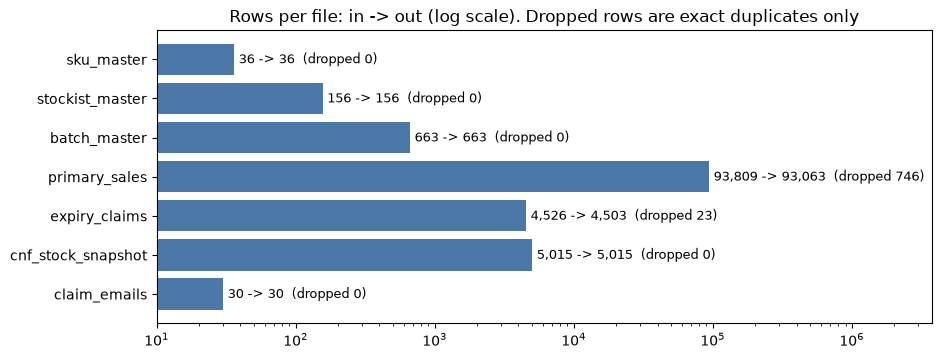

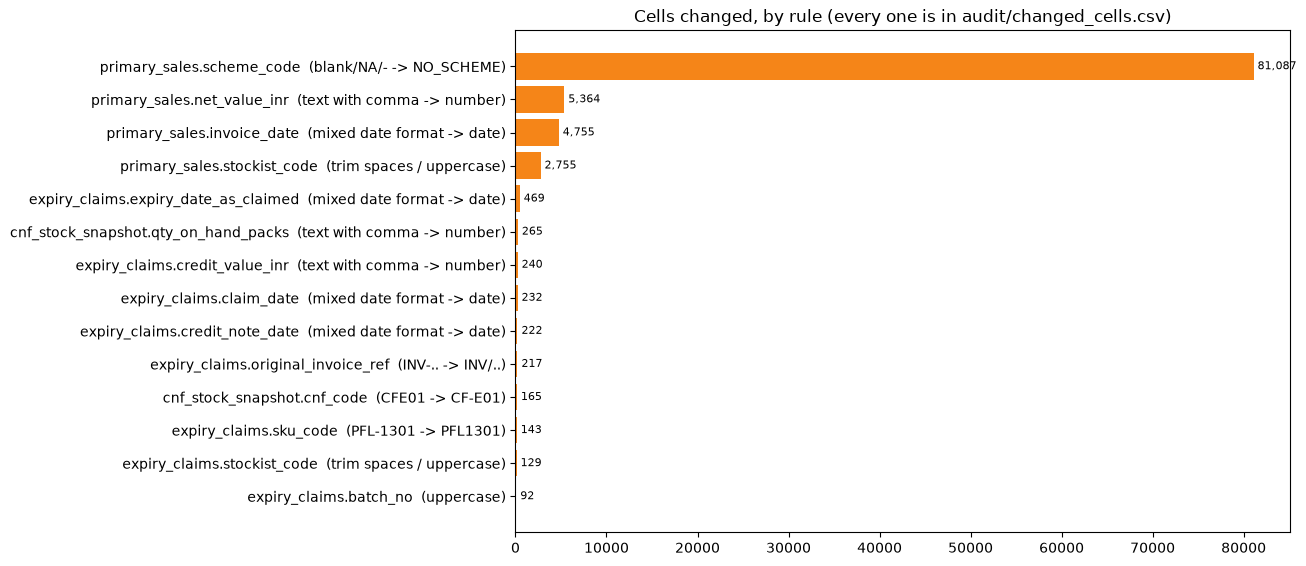

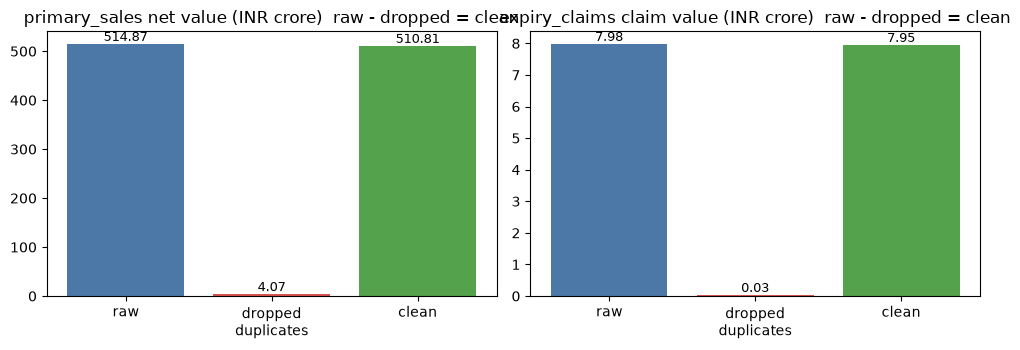

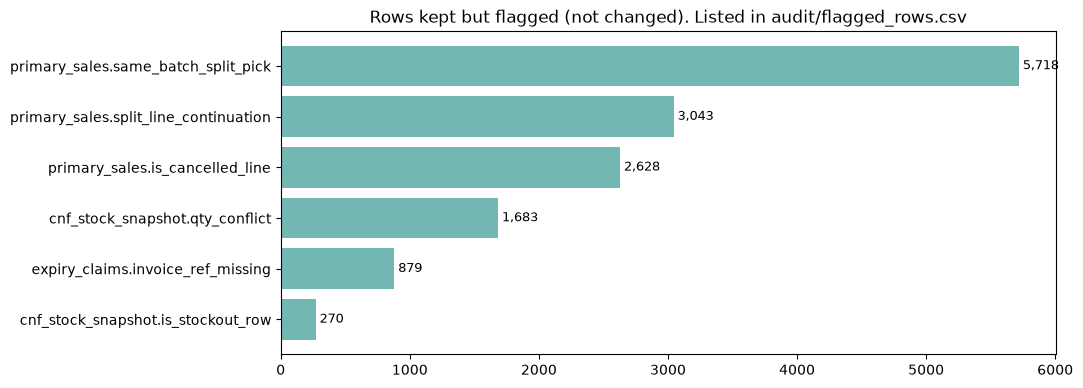

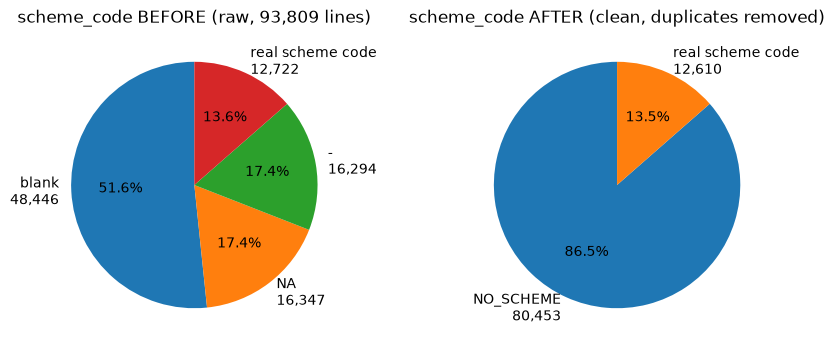

In [9]:
import io, base64
import matplotlib.pyplot as plt

FIGS = {}
s_ = summary[summary.file != 'TOTAL'].copy()

# 1. rows in -> out per file
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.barh(s_.file, s_.rows_in, color='#4c78a8')
ax.set_xscale('log'); ax.invert_yaxis()
for i, r in enumerate(s_.itertuples()):
    ax.text(r.rows_in * 1.08, i, f'{r.rows_in:,} -> {r.rows_out:,}  (dropped {r.rows_dropped:,})', va='center', fontsize=9)
ax.set_xlim(10, s_.rows_in.max() * 40)
ax.set_title('Rows per file: in -> out (log scale). Dropped rows are exact duplicates only')
FIGS['rows'] = fig; plt.show()

# 2. what was changed, by rule
ch = changes.groupby(['file', 'column', 'rule']).size().reset_index(name='cells').sort_values('cells')
fig, ax = plt.subplots(figsize=(10, 0.38 * len(ch) + 1.2))
ax.barh(ch.file + '.' + ch.column + '  (' + ch.rule + ')', ch.cells, color='#f58518')
for i, v in enumerate(ch.cells): ax.text(v, i, f' {v:,}', va='center', fontsize=8)
ax.set_title('Cells changed, by rule (every one is in audit/changed_cells.csv)')
FIGS['changes'] = fig; plt.show()

# 3. money bridge: raw -> dropped -> clean
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
for ax, (f, col, title) in zip(axes, [('primary_sales', 'net_value_inr', 'primary_sales net value'), ('expiry_claims', 'claim_value_inr', 'expiry_claims claim value')]):
    raw_v = num(RAW_ORIG[f][col]).sum() / 1e7
    drop_v = DROPPED[f][col].sum() / 1e7
    clean_v = clean[f][col].sum() / 1e7
    ax.bar(['raw', 'dropped\nduplicates', 'clean'], [raw_v, drop_v, clean_v], color=['#4c78a8', '#d9534f', '#54a24b'])
    for i, v in enumerate([raw_v, drop_v, clean_v]): ax.text(i, v, f'{v:,.2f}', ha='center', va='bottom', fontsize=9)
    ax.set_title(title + ' (INR crore)  raw - dropped = clean')
plt.tight_layout(); FIGS['money'] = fig; plt.show()

# 4. flagged rows
fl = flags.groupby(['file', 'flag']).size().reset_index(name='rows').sort_values('rows')
fig, ax = plt.subplots(figsize=(10, 0.5 * len(fl) + 1.2))
ax.barh(fl.file + '.' + fl.flag, fl.rows, color='#72b7b2')
for i, v in enumerate(fl.rows): ax.text(v, i, f' {v:,}', va='center', fontsize=9)
ax.set_title('Rows kept but flagged (not changed). Listed in audit/flagged_rows.csv')
FIGS['flags'] = fig; plt.show()

# 5. 'no scheme' before vs after (pie)
rawps = RAW_ORIG['primary_sales'].scheme_code.str.strip()
before = pd.Series({'blank': int((rawps == '').sum()), 'NA': int((rawps == 'NA').sum()), '-': int((rawps == '-').sum()),
                    'real scheme code': int((~rawps.isin(['', 'NA', '-'])).sum())})
after = clean['primary_sales'].scheme_code.map(lambda v: 'NO_SCHEME' if v == 'NO_SCHEME' else 'real scheme code').value_counts()
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].pie(before, labels=[f'{k}\n{v:,}' for k, v in before.items()], autopct='%1.1f%%', startangle=90)
axes[0].set_title('scheme_code BEFORE (raw, 93,809 lines)')
axes[1].pie(after, labels=[f'{k}\n{v:,}' for k, v in after.items()], autopct='%1.1f%%', startangle=90)
axes[1].set_title('scheme_code AFTER (clean, duplicates removed)')
FIGS['scheme'] = fig; plt.show()

**How to read these:** chart 1 must agree with the `audit_summary` table. Chart 3: `raw - dropped = clean` must hold (it does only because dropped rows are the only thing removed). Chart 5: the three "no scheme" slices before become one slice after; the real-scheme slice must not change in size (except for any duplicates removed).

## Row inspector: pick any row, see the raw row next to the clean row

In [10]:
def show_row(file, src_row):
    # Raw row (line number in the CSV file) next to its cleaned version, or a note if it was dropped.
    b = RAW_ORIG[file]; b = b[b.src_row == src_row]
    if b.empty: return 'no such row'
    c = clean[file]; c = c[c.src_row == src_row]
    out = pd.DataFrame({'raw (as in file)': b.iloc[0]})
    if c.empty:
        d = DROPPED[file]; d = d[d.src_row == src_row].iloc[0]
        out['clean'] = 'DROPPED: exact duplicate of source row %d' % d.duplicate_of_src_row
    else:
        out['clean'] = c.iloc[0].astype(str)
    out['changed?'] = [('' if str(x) == str(y) else '<<<') for x, y in zip(out.iloc[:, 0], out.iloc[:, 1])]
    return out

# 1) a random sample of changed cells: look at old -> new
sample = changes[~changes.row_later_dropped].sample(12, random_state=7)
display(sample[['file', 'src_row', 'key', 'column', 'old_value', 'new_value', 'rule']])

,file,src_row,key,column,old_value,new_value,rule
44803,primary_sales,36145,INV/E01/2503/031792,scheme_code,NA,NO_SCHEME,blank/NA/- -> NO_SCHEME
4987,primary_sales,8032,INV/N02/2406/005648,stockist_code,STK0038,STK0038,trim spaces / uppercase
7122,primary_sales,81548,INV/W01/2606/076517,stockist_code,STK0082,STK0082,trim spaces / uppercase
50257,primary_sales,41905,INV/S02/2505/038788,scheme_code,NA,NO_SCHEME,blank/NA/- -> NO_SCHEME
60039,primary_sales,53068,INV/S01/2509/050227,scheme_code,-,NO_SCHEME,blank/NA/- -> NO_SCHEME
80907,primary_sales,78028,INV/W01/2605/073338,scheme_code,,NO_SCHEME,blank/NA/- -> NO_SCHEME
87865,primary_sales,86349,INV/E01/2607/079342,scheme_code,,NO_SCHEME,blank/NA/- -> NO_SCHEME
72712,primary_sales,68470,INV/N01/2602/063024,scheme_code,,NO_SCHEME,blank/NA/- -> NO_SCHEME
15414,primary_sales,2542,INV/S01/2405/004325,scheme_code,,NO_SCHEME,blank/NA/- -> NO_SCHEME
54433,primary_sales,47462,INV/S01/2507/044637,scheme_code,NA,NO_SCHEME,blank/NA/- -> NO_SCHEME


In [11]:
# 2) change the numbers below to inspect any row. Example: first changed claim, and a dropped sales row
f1, r1 = 'expiry_claims', int(changes[(changes.file == 'expiry_claims') & ~changes.row_later_dropped].src_row.iloc[0])
display(HTML(f'<b>{f1}, source row {r1}</b>')); display(show_row(f1, r1))
r2 = int(DROPPED['primary_sales'].src_row.iloc[0])
display(HTML(f'<b>primary_sales, source row {r2} (a dropped duplicate)</b>')); display(show_row('primary_sales', r2))

,raw (as in file),clean,changed?
src_row,6,6,
claim_no,CLM-2404-04257,CLM-2404-04257,
claim_date,25-Apr-2024,2024-04-25 00:00:00,<<<
stockist_code,STK0039,STK0039,
cnf_code,CF-N02,CF-N02,
sku_code,PFL1602,PFL1602,
batch_no,L2360245,L2360245,
expiry_date_as_claimed,31-10-2026,2026-10-31 00:00:00,<<<
qty_claimed,44,44,
claim_value_inr,2824.8,2824.8,


,raw (as in file),clean,changed?
src_row,12,DROPPED: exact duplicate of source row 11,<<<
invoice_no,INV/E01/2404/001173,DROPPED: exact duplicate of source row 11,<<<
invoice_date,01-04-2024,DROPPED: exact duplicate of source row 11,<<<
cnf_code,CF-E01,DROPPED: exact duplicate of source row 11,<<<
stockist_code,STK0071,DROPPED: exact duplicate of source row 11,<<<
sku_code,PFL1502,DROPPED: exact duplicate of source row 11,<<<
batch_no,K2350213,DROPPED: exact duplicate of source row 11,<<<
ordered_qty,627,DROPPED: exact duplicate of source row 11,<<<
invoiced_qty,627,DROPPED: exact duplicate of source row 11,<<<
free_qty,0,DROPPED: exact duplicate of source row 11,<<<


## One-click report (HTML) and Excel proof workbook

In [12]:
import datetime, webbrowser, pathlib
OPEN_REPORT = True      # set False if you do not want the browser to open automatically

def fig_html(name, title):
    buf = io.BytesIO(); FIGS[name].savefig(buf, format='png', dpi=110, bbox_inches='tight')
    return f'<h3>{title}</h3><img src="data:image/png;base64,{base64.b64encode(buf.getvalue()).decode()}" style="max-width:100%">'

css = '<style>body{font-family:Segoe UI,Arial;margin:24px;max-width:1100px}table{border-collapse:collapse;font-size:12px}td,th{border:1px solid #ccc;padding:3px 7px;text-align:right}th{background:#f0f0f0}h2{margin-top:32px;border-bottom:2px solid #ddd}</style>'
now = datetime.datetime.now().strftime('%d %b %Y %H:%M')
html = [css, f'<h1>Step 3 verification report</h1><p>Generated {now} by step3_clean.ipynb. Raw files were only read. Every number below is reproduced from the files in this folder.</p>']
html.append('<h2>1. Rows in, dropped, out</h2>' + summary.to_html(index=False, border=0))
html.append(fig_html('rows', 'Rows per file'))
html.append('<h2>2. What changed</h2>' + fig_html('changes', 'Cells changed by rule'))
html.append('<h2>3. Money check</h2>' + fig_html('money', 'raw - dropped duplicates = clean'))
html.append('<h2>4. Flagged, not changed</h2>' + fig_html('flags', 'Flagged rows'))
html.append('<h2>5. scheme_code</h2>' + fig_html('scheme', 'Three spellings of no scheme became one'))
html.append('<h2>6. Rule log</h2>' + log_df.to_html(index=False, border=0))
html.append('<h2>7. Sample of changed cells (12 random)</h2>' + sample[['file', 'src_row', 'key', 'column', 'old_value', 'new_value', 'rule']].to_html(index=False, border=0))
for f, d in DROPPED.items():
    html.append(f'<h2>8. Dropped rows: {f} ({len(d)} rows, first 25 shown)</h2>' + d.head(25).to_html(index=False, border=0))
report = os.path.join(AUD, 'verification_report.html')
open(report, 'w', encoding='utf-8').write('\n'.join(html))

# Excel workbook with native charts
xlsx = os.path.join(AUD, 'audit_proof.xlsx')
by_rule = changes.groupby(['file', 'column', 'rule']).size().reset_index(name='cells')
by_rule['label'] = by_rule.file + '.' + by_rule.column
sch = pd.concat([before.rename('lines').reset_index().rename(columns={'index': 'category'}).assign(stage='before'),
                 after.rename('lines').reset_index().rename(columns={'scheme_code': 'category', 'index': 'category'}).assign(stage='after')])
with pd.ExcelWriter(xlsx, engine='xlsxwriter') as xw:
    summary.to_excel(xw, sheet_name='Summary', index=False)
    by_rule.to_excel(xw, sheet_name='ByRule', index=False)
    sch[sch.stage == 'before'][['category', 'lines']].to_excel(xw, sheet_name='SchemeBefore', index=False)
    sch[sch.stage == 'after'][['category', 'lines']].to_excel(xw, sheet_name='SchemeAfter', index=False)
    log_df.to_excel(xw, sheet_name='RuleLog', index=False)
    for f, d in DROPPED.items(): d.to_excel(xw, sheet_name=('Dropped_' + f)[:31], index=False)
    flags.to_excel(xw, sheet_name='Flagged', index=False)
    changes.to_excel(xw, sheet_name='ChangedCells', index=False)
    wb = xw.book
    n = len(s_)
    c1 = wb.add_chart({'type': 'column'})
    for col, name in [(1, 'rows_in'), (2, 'rows_dropped'), (3, 'rows_out')]:
        c1.add_series({'name': name, 'categories': ['Summary', 1, 0, n, 0], 'values': ['Summary', 1, col, n, col]})
    c1.set_title({'name': 'Rows in / dropped / out per file'}); c1.set_y_axis({'log_base': 10}); c1.set_size({'width': 760, 'height': 320})
    xw.sheets['Summary'].insert_chart('K2', c1)
    c2 = wb.add_chart({'type': 'bar'})
    c2.add_series({'name': 'cells changed', 'categories': ['ByRule', 1, 5, len(by_rule), 5], 'values': ['ByRule', 1, 3, len(by_rule), 3]})
    c2.set_title({'name': 'Cells changed by file.column'}); c2.set_size({'width': 760, 'height': 420})
    xw.sheets['ByRule'].insert_chart('H2', c2)
    for sh, ttl in [('SchemeBefore', 'scheme_code BEFORE'), ('SchemeAfter', 'scheme_code AFTER')]:
        pc = wb.add_chart({'type': 'pie'}); rows_n = len(sch[sch.stage == ('before' if 'Before' in sh else 'after')])
        pc.add_series({'categories': [sh, 1, 0, rows_n, 0], 'values': [sh, 1, 1, rows_n, 1], 'data_labels': {'percentage': True, 'category': True}})
        pc.set_title({'name': ttl}); xw.sheets[sh].insert_chart('D2', pc)

for p in (report, xlsx): assert os.path.getsize(p) > 0, p
print('HTML report :', pathlib.Path(report).resolve())
print('Excel proof :', pathlib.Path(xlsx).resolve())
if OPEN_REPORT:
    try: webbrowser.open(pathlib.Path(report).resolve().as_uri())
    except Exception as e: print('could not open browser:', e)

HTML report : D:\FDE\Assignments\langgraph\pfizer-channel-engagement_learner-pack\data-clean\audit\verification_report.html
Excel proof : D:\FDE\Assignments\langgraph\pfizer-channel-engagement_learner-pack\data-clean\audit\audit_proof.xlsx


**Check:** charts appear above, the browser opens the report, and `audit_proof.xlsx` opens in Excel with a bar chart on `Summary`, a bar chart on `ByRule` and two pies on `SchemeBefore` / `SchemeAfter`. The numbers on the charts must match the printed `audit_summary` table.

## 3.3g Validate: did the cleaning do what we said?

Every line below is an `assert`. If one fails, Jupyter stops with an error. All passing means the cleaned files are consistent with our rules.

In [13]:
# row counts: raw minus exact duplicates dropped
assert len(ps) == 93809 - 746,  len(ps)
assert len(ec) == 4526 - 23,    len(ec)
assert len(sn) == 5015 and len(bat) == 663 and len(sku) == 36 and len(stk) == 156 and len(em) == 30

# dates are real dates now, not text
for df, cols in [(ps,['invoice_date']), (ec,['claim_date','expiry_date_as_claimed','credit_note_date']),
                 (bat,['mfg_date','expiry_date']), (sn,['snapshot_date','expiry_date'])]:
    for c in cols: assert str(df[c].dtype).startswith('datetime64'), (c, df[c].dtype)

# codes
assert not ps.stockist_code.str.contains(r'\s|[a-z]').any() and not ec.stockist_code.str.contains(r'\s|[a-z]').any()
assert not ec.sku_code.str.contains('-').any()
assert set(sn.cnf_code) == {'CF-E01','CF-N01','CF-N02','CF-S01','CF-S02','CF-W01'}, set(sn.cnf_code)
assert not ec.batch_no.str.contains('[a-z]').any()
assert not ec.original_invoice_ref.str.startswith('INV-').any()

# scheme and numbers
assert not ps.scheme_code.isin(['', 'NA', '-']).any()
assert ec.credit_value_inr.dtype.kind == 'f' and ps.net_value_inr.dtype.kind == 'f' and sn.qty_on_hand_packs.dtype.kind == 'f'

# no exact duplicates remain, and no rows lost or invented beyond the log
assert not ps.drop(columns=['src_row','is_cancelled_line','split_line_continuation','same_batch_split_pick']).duplicated().any()
assert not ec.drop(columns=['src_row','invoice_ref_missing']).duplicated().any()

# money did not change except for the dropped duplicates
raw_net = num(raw['primary_sales'].net_value_inr).sum()
print('primary net value raw       :', f'{raw_net:,.0f}')
print('primary net value clean     :', f'{ps.net_value_inr.sum():,.0f}')
print('difference (= dropped dups) :', f'{raw_net - ps.net_value_inr.sum():,.0f}')
print('NO_SCHEME lines             :', int((ps.scheme_code == 'NO_SCHEME').sum()))
print('ALL CHECKS PASSED')

primary net value raw       : 5,148,736,777
primary net value clean     : 5,108,059,709
difference (= dropped dups) : 40,677,069
NO_SCHEME lines             : 80453
ALL CHECKS PASSED


**Check:** `ALL CHECKS PASSED` prints. The difference line should be about 40.7 million INR (about 4.07 crore), the value of the dropped duplicate lines, and it should equal the sum in `dropped_duplicates_primary_sales.csv`.

Next: 3.4 link checks (do the codes in one file exist in the others?), then 3.5 data dictionary and data-quality log.